# Checkboard detection

In [61]:
import numpy as np
import cv2 as cv
import glob
# termination criteria
criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 30, 0.001)
# prepare object points, like (0,0,0), (1,0,0), (2,0,0) ....,(6,5,0)
pattern_size = (9, 6)
objp = np.zeros((pattern_size[0] * pattern_size[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:pattern_size[0], 0:pattern_size[1]].T.reshape(-1, 2)
# Arrays to store object points and image points from all the images.
objpoints = [] # 3d point in real world space
imgpoints = [] # 2d points in image plane.
images = glob.glob('pictures/*.jpeg')
for fname in images:
    img = cv.imread(fname)
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    # Find the chess board corners
    ret, corners = cv.findChessboardCorners(gray, pattern_size, None)
    # If found, add object points, image points (after refining them)
    if ret == True:
        objpoints.append(objp)
        corners2 = cv.cornerSubPix(gray,corners, (11,11), (-1,-1), criteria)
        imgpoints.append(corners2)
        # Draw and display the corners
        cv.drawChessboardCorners(img, pattern_size, corners2, ret)
        # save figure
        cv.imwrite('output/' + fname.split('/')[-1], img)

        cv.waitKey(500)
cv.destroyAllWindows()


In [62]:
objpoints

[array([[0., 0., 0.],
        [1., 0., 0.],
        [2., 0., 0.],
        [3., 0., 0.],
        [4., 0., 0.],
        [5., 0., 0.],
        [6., 0., 0.],
        [7., 0., 0.],
        [8., 0., 0.],
        [0., 1., 0.],
        [1., 1., 0.],
        [2., 1., 0.],
        [3., 1., 0.],
        [4., 1., 0.],
        [5., 1., 0.],
        [6., 1., 0.],
        [7., 1., 0.],
        [8., 1., 0.],
        [0., 2., 0.],
        [1., 2., 0.],
        [2., 2., 0.],
        [3., 2., 0.],
        [4., 2., 0.],
        [5., 2., 0.],
        [6., 2., 0.],
        [7., 2., 0.],
        [8., 2., 0.],
        [0., 3., 0.],
        [1., 3., 0.],
        [2., 3., 0.],
        [3., 3., 0.],
        [4., 3., 0.],
        [5., 3., 0.],
        [6., 3., 0.],
        [7., 3., 0.],
        [8., 3., 0.],
        [0., 4., 0.],
        [1., 4., 0.],
        [2., 4., 0.],
        [3., 4., 0.],
        [4., 4., 0.],
        [5., 4., 0.],
        [6., 4., 0.],
        [7., 4., 0.],
        [8., 4., 0.],
        [0

In [63]:
imgpoints

[array([[1334.5316 ,  846.64716],
        [1253.6069 ,  858.36597],
        [1167.6993 ,  870.4463 ],
        [1075.298  ,  883.87274],
        [ 974.4047 ,  898.63245],
        [ 864.8332 ,  915.19806],
        [ 740.8345 ,  932.9043 ],
        [ 606.41724,  954.58923],
        [ 454.78162,  978.50214],
        [1324.6187 ,  740.55804],
        [1241.3738 ,  747.8214 ],
        [1160.2382 ,  755.6522 ],
        [1065.723  ,  763.6917 ],
        [ 963.46674,  772.4028 ],
        [ 857.5895 ,  782.7378 ],
        [ 735.9254 ,  794.32135],
        [ 600.1702 ,  807.61646],
        [ 450.55658,  823.20764],
        [1311.2039 ,  636.2615 ],
        [1231.7786 ,  639.5958 ],
        [1152.3821 ,  642.36053],
        [1055.971  ,  646.40704],
        [ 955.46735,  650.12915],
        [ 849.3636 ,  654.32074],
        [ 727.4828 ,  659.7504 ],
        [ 595.02893,  665.3632 ],
        [ 446.01385,  671.41534],
        [1298.3733 ,  533.72473],
        [1225.8824 ,  531.6419 ],
        [1142.

# Camera calibration

## calculate H for each image

In [64]:
projection_matrices = []
for i in range(len(objpoints)):
    # get the object points and image points for the current image
    objp = objpoints[i]
    imgp = imgpoints[i]
    M = []
    for j in range(len(objp)):
        u, v = imgp[j].ravel()
        x, y = objp[j][:2]

        M.append([-x, -y, -1, 0, 0, 0, u*x, u*y, u])
        M.append([0, 0, 0, -x, -y, -1, v*x, v*y, v])
    U, S, Vt = np.linalg.svd(M)
    H = Vt[-1].reshape(3, 3)
    projection_matrices.append(H)


In [65]:
projection_matrices

[array([[-8.03037485e-02,  5.75502054e-05,  8.40117593e-01],
        [-1.36353413e-02, -6.26215294e-02,  5.32584227e-01],
        [-2.45609058e-05,  5.39139001e-06,  6.29944279e-04]]),
 array([[ 5.45638202e-02,  1.95777348e-02, -7.39651583e-01],
        [-1.14393577e-03,  9.10149529e-02, -6.64281266e-01],
        [-2.50402169e-05,  2.69906129e-05, -6.36809527e-04]]),
 array([[-7.25179056e-02, -1.30515421e-02,  7.85879120e-01],
        [-6.16813767e-03, -7.16425618e-02,  6.09748880e-01],
        [-1.26016258e-05, -2.15721018e-05,  6.48405317e-04]]),
 array([[-6.40114872e-02, -2.29055215e-02,  7.72605066e-01],
        [ 1.31440746e-03, -7.78311683e-02,  6.26417985e-01],
        [ 5.80527971e-06, -2.70555084e-05,  6.06079983e-04]]),
 array([[ 4.95473135e-02, -5.13821348e-03, -7.60253395e-01],
        [-1.70576558e-02,  8.99730932e-02, -6.41207364e-01],
        [-3.70740208e-05,  5.19206722e-07, -6.56977089e-04]]),
 array([[ 9.16420873e-02, -4.18806204e-02, -8.70170927e-01],
        [-1.52

### Test the projection matrices by projecting the object points to image points

In [66]:
for i, H in enumerate(projection_matrices):
    objp_i = objpoints[i]
    imgp_i = imgpoints[i]

    projected_points = []

    for x, y, _ in objp_i:
        p = np.array([x, y, 1.0])
        p_projected = H @ p
        p_projected /= p_projected[2]
        projected_points.append(p_projected[:2])

    for j, projected in enumerate(projected_points):
        print(
            f"Image {i}, Point {j}: "
            f"Actual: {imgp_i[j]}, Projected: {projected}"
        )

Image 0, Point 0: Actual: [1334.5316   846.64716], Projected: [1333.63794467  845.44656554]
Image 0, Point 1: Actual: [1253.6069   858.36597], Projected: [1255.09533065  857.22355264]
Image 0, Point 2: Actual: [1167.6993  870.4463], Projected: [1169.91014388  869.99655311]
Image 0, Point 3: Actual: [1075.298    883.87274], Projected: [1077.20250547  883.89749943]
Image 0, Point 4: Actual: [974.4047  898.63245], Projected: [975.92995916 899.08270159]
Image 0, Point 5: Actual: [864.8332  915.19806], Projected: [864.848103   915.73875007]
Image 0, Point 6: Actual: [740.8345 932.9043], Projected: [742.45919914 934.09022156]
Image 0, Point 7: Actual: [606.41724 954.58923], Projected: [606.94424896 954.40986383]
Image 0, Point 8: Actual: [454.78162 978.50214], Projected: [456.07197531 977.03224332]
Image 0, Point 9: Actual: [1324.6187   740.55804], Projected: [1322.41141917  739.7077177 ]
Image 0, Point 10: Actual: [1241.3738  747.8214], Projected: [1244.11066227  747.1287026 ]
Image 0, Poin

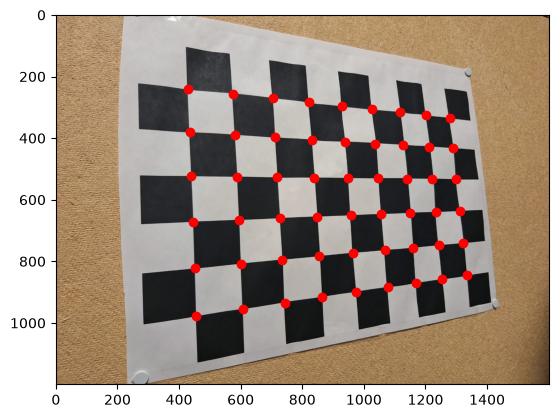

In [70]:
# take an image as an example and display the original image with the projected points
import matplotlib.pyplot as plt
img = cv.imread(images[0])
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
H = projection_matrices[0]
objp_i = objpoints[0]
projected_points = []
for j in range(len(objp_i)):
    x, y, _ = objp_i[j]
    p = np.array([x, y, 1.0])
    p_projected = H @ p
    p_projected /= p_projected[2]
    projected_points.append(p_projected[:2])
for point in projected_points:
    plt.plot(point[0], point[1], 'ro')
plt.show()

## Use the projection matrices to compute the intrinsic and extrinsic parameters of the camera.

In [67]:
V = []
for i in range(len(objpoints)):
    H = projection_matrices[i]
    h1 = H[:, 0]
    h2 = H[:, 1]
    v12 = np.array([h1[0]*h2[0], h1[0]*h2[1] + h1[1]*h2[0], h1[1]*h2[1], h1[2]*h2[0] + h1[0]*h2[2], h1[2]*h2[1] + h1[1]*h2[2], h1[2]*h2[2]])
    v11 = np.array([h1[0]*h1[0], h1[0]*h1[1] + h1[1]*h1[0], h1[1]*h1[1], h1[2]*h1[0] + h1[0]*h1[2], h1[2]*h1[1] + h1[1]*h1[2], h1[2]*h1[2]])
    v22 = np.array([h2[0]*h2[0], h2[0]*h2[1] + h2[1]*h2[0], h2[1]*h2[1], h2[2]*h2[0] + h2[0]*h2[2], h2[2]*h2[1] + h2[1]*h2[2], h2[2]*h2[2]])
    V.append(v12)
    V.append(v11 - v22)
U, S, Vt = np.linalg.svd(V)

A = Vt[-1] # A is upper triangular matrix
# convert to full matrix
A = np.array([[A[0], A[1], A[3]], [0, A[2], A[4]], [0, 0, A[5]]])
K = np.linalg.inv(A)

In [68]:
K

array([[-2.28939488e+06, -1.07968042e+03, -8.06086239e+02],
       [-0.00000000e+00, -2.27475017e+06, -6.02294023e+02],
       [-0.00000000e+00, -0.00000000e+00, -1.00000010e+00]])